In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")
df.shape


(7043, 21)

In [40]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [41]:
df.isna().sum()
df.duplicated().sum()

#Checking duplicate copies, understanding correlation
total_charges_numeric = pd.to_numeric(df.TotalCharges,errors='coerce')
total_charges_numeric.isna().sum()
df.loc[total_charges_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]
(df["tenure"] == 0).sum()
df.loc[df["tenure"] == 0, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [42]:
# Data Cleaning
df_clean = df.copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean.TotalCharges, errors='coerce')
#print(df_clean["TotalCharges"].dtype)
#print(df_clean.shape)
df_clean.loc[df_clean["tenure"] == 0, "TotalCharges"] = df_clean.loc[df_clean["tenure"] == 0, "TotalCharges"].fillna(0)
#print(df_clean["TotalCharges"].isna().sum())


### Data Quality: `TotalCharges`

**Issue identified:**
- The dataset contains 7,043 customer records with no initially detected null values.
- However, `TotalCharges` was stored as a string column despite representing numerical billing information.
- Converting the column to numeric using `pd.to_numeric(errors="coerce")` revealed **11 invalid (blank) values**.
- Investigation showed that all 11 affected customers have `tenure = 0`, and these are the only customers with zero tenure.

**Interpretation:**

The missing `TotalCharges` values appear to be systematically associated with newly created customer accounts. Although these customers have nonzero `MonthlyCharges`, they may not have completed their first billing cycle, leaving their accumulated charges unrecorded.

**Cleaning decision:**

1. Convert `TotalCharges` to a numeric (`float64`) column.
2. Replace missing `TotalCharges` values with zero only for customers with `tenure = 0`.
3. Preserve all 7,043 customer records.

**Rationale:** Zero imputation is consistent with the assumption that newly created accounts have not yet accumulated charges. It avoids discarding valid customer records or imputing unrealistic median billing amounts.

**Verification:** After cleaning, `TotalCharges` contains zero missing values, and the dataset retains its original shape of `(7043, 21)`.

**Limitation:** The interpretation of zero accumulated charges is a business assumption, not a confirmed dataset rule. Future preprocessing should distinguish zero-tenure accounts from other cases of missing billing information.

In [49]:
df_clean["Churn"].unique()
print(df_clean["Churn"].value_counts())
df_clean["Churn"].value_counts(normalize=True)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

### Target Variable: Churn Distribution

The target variable `Churn` is binary, with two categories:

| Class | Customers | Proportion |
|---|---:|---:|
| No Churn | 5,174 | 73.46% |
| Churn | 1,869 | 26.54% |

The dataset exhibits moderate class imbalance, with approximately 2.8 non-churning customers for every churned customer.

A majority-class classifier predicting `No` for every observation would achieve 73.46% accuracy while failing to identify any actual churners.

**Modeling implications:**
- Accuracy alone is insufficient for evaluating churn prediction.
- We will prioritize PR-AUC (Average Precision) and evaluate precision, recall, F1, and ROC-AUC.
- Because retention outreach capacity is limited, we will also evaluate Recall@K and Precision@K for the highest-risk customers.
- We will use stratified train/validation/test splits to maintain approximately consistent class proportions.

C:\Users\Aishee Mondal\AppData\Local\Temp\ipykernel_22052\3485367088.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_clean, x="Churn", stat="percent", palette="viridis")


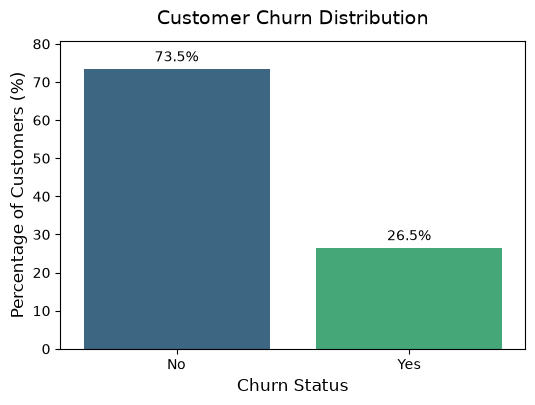

In [68]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x="Churn", stat="percent", palette="viridis")

for container in ax.containers:
      ax.bar_label(container, fmt="%.1f%%" , padding=3)
      
ax.set_title("Customer Churn Distribution", fontsize=14, pad=12)
ax.set_xlabel("Churn Status", fontsize=12)
ax.set_ylabel("Percentage of Customers (%)", fontsize=12)

ax.margins(y=0.1)

plt.show()

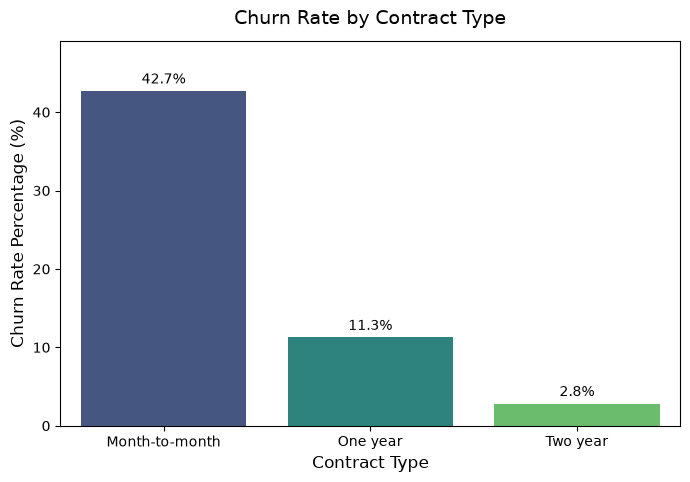

In [82]:
# correlation of churn with contract type and plot
df_clean["Contract"].unique()
df_clean["Contract"].value_counts()
churn_by_contract = df_clean.assign(
        Churn_Flag=df_clean["Churn"].map({"Yes": 1, "No": 0})
        ).groupby("Contract", as_index=False)["Churn_Flag"].mean()
churn_by_contract["Churn_Rate"] = churn_by_contract["Churn_Flag"]*100

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=churn_by_contract,
    x="Contract",
    y="Churn_Rate",
    hue="Contract",
    palette="viridis",
    legend=False,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%",padding=3)
    
ax.set_title("Churn Rate by Contract Type", fontsize=14, pad=12)
ax.set_xlabel("Contract Type", fontsize=12)
ax.set_ylabel("Churn Rate Percentage (%)", fontsize=12)

ax.set_ylim(0, churn_by_contract["Churn_Rate"].max() * 1.15)
plt.show()


### Churn Analysis by Contract Type

**Objective:** Examine whether contract duration is associated with customer churn.

| Contract Type | Churn Rate |
|---|---:|
| Month-to-month | 42.7% |
| One year | 11.3% |
| Two year | 2.8% |

**Key findings:**
- Month-to-month customers exhibit the highest churn rate (42.7%), compared with 11.3% for one-year contracts and 2.8% for two-year contracts.
- Churn rates decrease substantially as contract duration increases.
- Contract type appears to be a potentially informative feature for predicting churn.

**Business interpretation:** Customers on flexible month-to-month plans may be more likely to discontinue service, while customers with longer contracts exhibit greater retention.

**Modeling consideration:** This relationship is observational, not causal. Contract type may also be associated with customer tenure and other characteristics, which we will investigate in subsequent analysis.

29.0


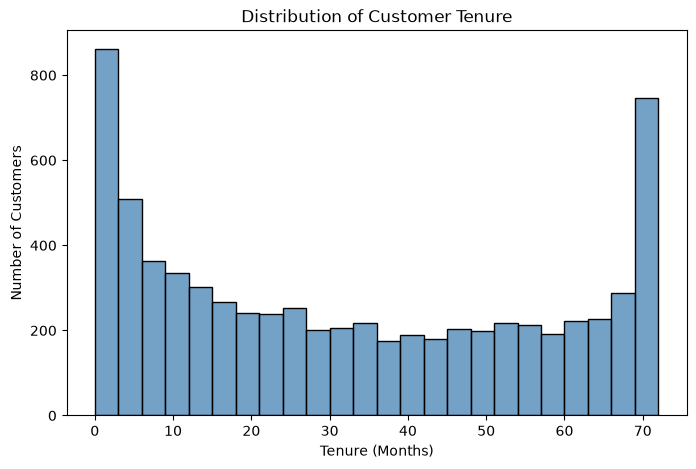

In [87]:
# Understand correlation of target variable "Churn" with the numerical distribution of "tenure"
df_clean["tenure"].describe()
print(df_clean["tenure"].median())
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    bins=24,
    color="steelblue"
)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

       count       mean  median  min  max
Churn                                    
No      5174  37.569965    38.0    0   72
Yes     1869  17.979133    10.0    1   72


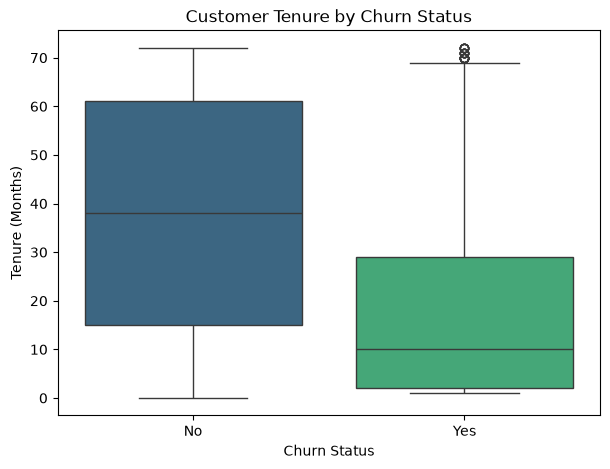

In [92]:
tenure_by_churn = df_clean.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(tenure_by_churn)

# Boxplot
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="viridis",
    legend=False
)
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

In [93]:
# Create temporary tenure groups
tenure_eda = df_clean.assign(
    TenureGroup=pd.cut(
        df_clean["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Developing", "Established", "Long-term"]
    ),
    Churn_Flag=(df_clean["Churn"] == "Yes").astype(int)
)

# Calculate churn rates within each tenure group
churn_by_tenure = (
    tenure_eda
    .groupby("TenureGroup", observed=True)
    .agg(
        Customers=("Churn_Flag", "size"),
        Churned=("Churn_Flag", "sum"),
        Churn_Rate=("Churn_Flag", "mean")
    )
    .reset_index()
)

churn_by_tenure["Churn_Rate"] *= 100

print(churn_by_tenure)

   TenureGroup  Customers  Churned  Churn_Rate
0          New       2186     1037   47.438243
1   Developing       1024      294   28.710938
2  Established       1594      325   20.388959
3    Long-term       2239      213    9.513176


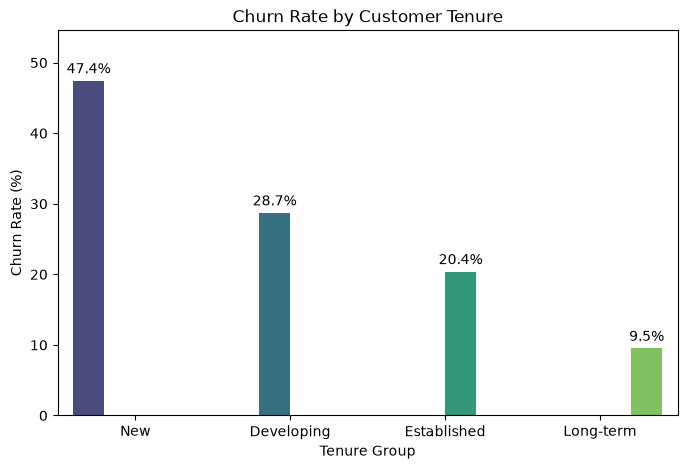

In [94]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=churn_by_tenure,
    x="TenureGroup",
    y="Churn_Rate",
    hue="TenureGroup",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Churn Rate by Customer Tenure")
ax.set_xlabel("Tenure Group")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, churn_by_tenure["Churn_Rate"].max() * 1.15)

plt.show()

### Customer Tenure and Churn Analysis

**Objective:** Investigate the distribution of customer tenure and its association with churn.

#### 1. Tenure Distribution

Customer tenure ranges from 0 to 72 months, with an overall median of 29 months.

The distribution is roughly U-shaped, with relatively high concentrations of newly acquired customers and long-tenured customers, particularly near 72 months.

#### 2. Tenure by Churn Status

| Metric | No Churn | Churn |
|---|---:|---:|
| Mean tenure | 37.57 months | 17.98 months |
| Median tenure | 38 months | 10 months |

Customers who churned generally have substantially shorter tenure than customers who remained. The median tenure differs by 28 months between the two groups.

This suggests a meaningful association between shorter customer tenure and churn.

#### 3. Churn Rates by Tenure Group

| Tenure Group | Customers | Churn Rate |
|---|---:|---:|
| New (0–12 months) | 2,186 | 47.4% |
| Developing (13–24 months) | 1,024 | 28.7% |
| Established (25–48 months) | 1,594 | 20.4% |
| Long-term (49–72 months) | 2,239 | 9.5% |

Churn rates decrease consistently across increasing tenure groups. New customers exhibit the highest churn rate (47.4%), while long-term customers have the lowest (9.5%).

Approximately 55.5% of observed churn cases occur among customers with tenure of 12 months or less.

#### 4. Business and Modeling Implications

- Shorter tenure is strongly associated with higher observed churn rates, making tenure a potentially valuable predictive feature.
- Early-tenure customers may be an important group to prioritize when evaluating retention strategies.
- Tenure and contract duration may be related; their relationships should be investigated before drawing conclusions about their independent contributions.
- Tenure should initially remain a continuous numerical feature for modeling. The grouped categories were created for interpretability during EDA.

**Limitation:** These results describe associations in a cross-sectional dataset, not causal relationships or longitudinal survival probabilities. Further modeling is needed to evaluate the predictive contribution of tenure while accounting for other variables.

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64
Median Monthly Charges: 70.35


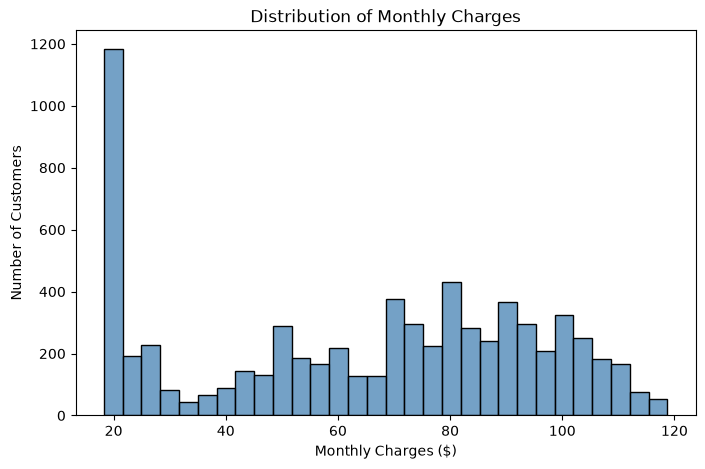

In [97]:
# Summary statistics
print(df_clean["MonthlyCharges"].describe())
print("Median Monthly Charges:", df_clean["MonthlyCharges"].median())

# Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="MonthlyCharges",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Number of Customers")
plt.show()

       count       mean  median    min     max
Churn                                         
No      5174  61.265124  64.425  18.25  118.75
Yes     1869  74.441332  79.650  18.85  118.35


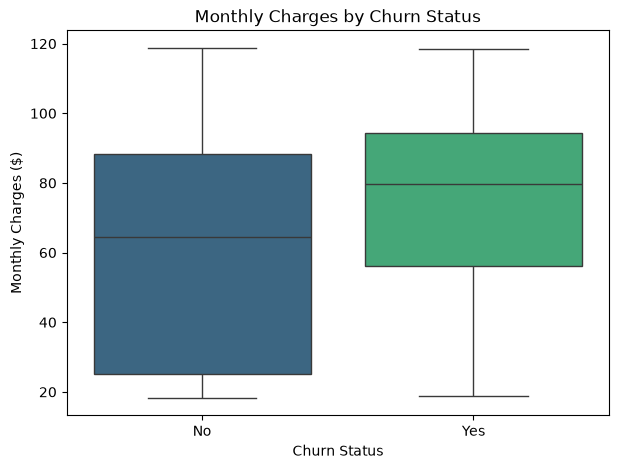

0.00     18.25
0.25     35.50
0.50     70.35
0.75     89.85
1.00    118.75
Name: MonthlyCharges, dtype: float64
    ChargeGroup  Customers  Churned  Churn_Rate
0   Q1 (Lowest)       1762      198   11.237230
1            Q2       1766      434   24.575311
2            Q3       1757      659   37.507114
3  Q4 (Highest)       1758      578   32.878271


In [101]:
# Summary statistics by churn status
charges_by_churn = df_clean.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(charges_by_churn)

# Boxplot
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="viridis",
    legend=False
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")
plt.show()


print(
    df_clean["MonthlyCharges"].quantile(
        [0, 0.25, 0.5, 0.75, 1]
    )
)

# Temporary grouped DataFrame for EDA
charge_eda = df_clean.assign(
    ChargeGroup=pd.qcut(
        df_clean["MonthlyCharges"],
        q=4,
        labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"]
    ),
    Churn_Flag=(df_clean["Churn"] == "Yes").astype(int)
)

# Calculate churn rates
churn_by_charges = (
    charge_eda
    .groupby("ChargeGroup", observed=True)
    .agg(
        Customers=("Churn_Flag", "size"),
        Churned=("Churn_Flag", "sum"),
        Churn_Rate=("Churn_Flag", "mean")
    )
    .reset_index()
)

churn_by_charges["Churn_Rate"] *= 100

print(churn_by_charges)

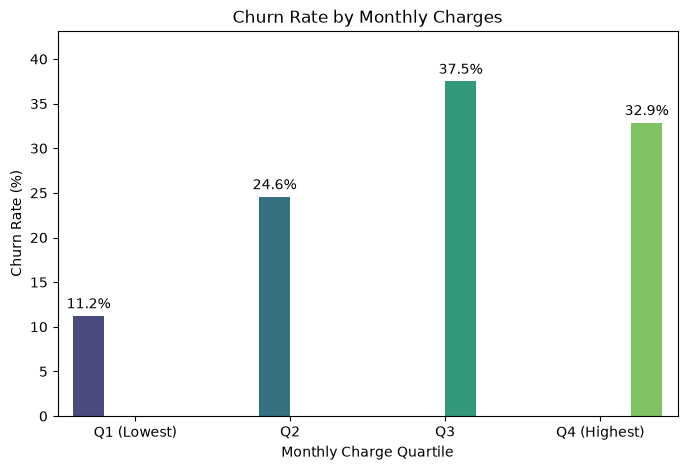

In [102]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=churn_by_charges,
    x="ChargeGroup",
    y="Churn_Rate",
    hue="ChargeGroup",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

ax.set_title("Churn Rate by Monthly Charges")
ax.set_xlabel("Monthly Charge Quartile")
ax.set_ylabel("Churn Rate (%)")

ax.set_ylim(0, churn_by_charges["Churn_Rate"].max() * 1.15)

plt.show()

### Monthly Charges and Churn Analysis

**Objective:** Investigate the distribution of monthly customer charges and their association with churn.

#### 1. Monthly Charges Distribution

Monthly charges range from $18.25 to $118.75, with a mean of $64.76 and a median of $70.35.

The distribution is non-normal and exhibits distinct concentrations around $20/month and approximately $70–$105/month. These clusters may reflect different service packages or subscription configurations.

#### 2. Monthly Charges by Churn Status

| Metric | No Churn | Churn |
|---|---:|---:|
| Mean Monthly Charges | $61.27 | $74.44 |
| Median Monthly Charges | $64.43 | $79.65 |

Customers who churned had higher monthly charges on average, with a mean difference of approximately $13.18/month and a median difference of $15.23/month.

#### 3. Churn Rates by Monthly Charge Quartile

| Charge Quartile | Customers | Churn Rate |
|---|---:|---:|
| Q1 (Lowest) | 1,762 | 11.2% |
| Q2 | 1,766 | 24.6% |
| Q3 | 1,757 | 37.5% |
| Q4 (Highest) | 1,758 | 32.9% |

Churn rates increase from Q1 through Q3 but decrease slightly in Q4, suggesting a nonlinear association between monthly charges and churn.

#### 4. Business and Modeling Implications

- Higher monthly charges are generally associated with increased observed churn risk.
- Customers in Q3 exhibit the highest churn rate, rather than those in the most expensive quartile.
- Differences in subscribed services, internet type, or contract duration may partly explain these patterns.
- `MonthlyCharges` should initially remain a continuous numerical feature for modeling.
- We will compare linear and tree-based models to evaluate whether nonlinear relationships improve predictive performance.

**Limitation:** These findings are observational. Higher monthly charges cannot be assumed to cause churn, and the independent predictive value of this feature has not yet been established.